# TP2: Predicción del % de equipos con firmware fuera de estándar por puerto PON

**Aprendizaje Automático y Grandes Datos, UNRaf, 2026. Objetivo 9.**

**Problema.** En cada uno de los 301 puertos PON de la red GPON, estimar qué proporción de las ONTs tiene una
versión de firmware distinta de la versión estándar de su modelo. Es una variable numérica continua entre 0 y 1, así
que es un problema de **regresión**.

**Relevancia.** Actualizar equipo por equipo es lento. Lo práctico es actualizar un puerto entero en una ventana de
mantenimiento. Si el modelo estima qué puertos tienen más equipos fuera de estándar, la empresa sabe por dónde empezar.

**Origen en el TP1.** En el TP1 vimos que el modelo de ONT instalado depende mucho de la localidad (respaldo R2). Si
la composición de modelos cambia según la zona, y el firmware depende del modelo, la composición de cada puerto
debería anticipar cuánto firmware desactualizado tiene.

**Definición del estándar (fija, del equipo).** El firmware estándar de un modelo es su versión más frecuente en todo
el inventario. Es una regla de negocio, no un parámetro aprendido, y se reemplaza si la empresa define otra.
⚠️ "Fuera de estándar" no siempre significa "más viejo": en el EG8143A5 el estándar es la V3 y muchos equipos tienen
V5 (ver la Fase 2 y la sección 11).

**Cómo está organizado.** La lógica vive en `src/tp2_regresion.py`. Este notebook la llama paso a paso y muestra cada
resultado. Todas las cifras se guardan en `results/metrics.json`.

In [1]:
# Configuración: rutas, semillas y librerías. El notebook se puede abrir desde notebooks/ o desde la raíz.
import os, sys
from pathlib import Path

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(RAIZ)
sys.path.insert(0, str(RAIZ / "src"))

%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

import tp2_regresion as t2          # funciones del TP2 (mismo código que corre run_all.py)
pd.set_option("display.width", 200, "display.max_columns", 30, "display.precision", 3)
print("Semilla:", t2.SEED, "| carpeta del proyecto:", RAIZ.name)

Semilla: 42 | carpeta del proyecto: tp-gpon


## 1. Datos

Cada fila es un **puerto PON** (Localidad + Slot + PON), armado en la Fase 1 (`data/processed/pons.csv`) a partir de las
5114 ONTs del inventario. La variable objetivo es `pct_fw_fuera`: la proporción de equipos del puerto cuyo firmware no es
el estándar de su modelo.

In [2]:
# Cargamos la tabla de PON y describimos la variable objetivo.
pons = t2.cargar_pons()
print(f"{len(pons)} PON x {pons.shape[1]} columnas")
display(pons[["pon_key", "Localidad", "Slot", "onts", "pct_moderno", "pct_catv", "n_modelos", t2.OBJETIVO]].head())
display(pons[t2.OBJETIVO].describe().to_frame("pct_fw_fuera").T)
print("PON con 0 % fuera de estándar:", int((pons[t2.OBJETIVO] == 0).sum()),
      "| PON con 100 %:", int((pons[t2.OBJETIVO] == 1).sum()))

301 PON x 36 columnas


,pon_key,Localidad,Slot,onts,pct_moderno,pct_catv,n_modelos,pct_fw_fuera
0,Bernardo de Irigoyen|0/|0/,Bernardo de Irigoyen,0/,45,0.00,0.156,7,0.289
1,Bernardo de Irigoyen|0/|2/,Bernardo de Irigoyen,0/,49,0.02,0.163,8,0.245
2,Bernardo de Irigoyen|0/|3/,Bernardo de Irigoyen,0/,33,0.03,0.061,5,0.121
3,Bernardo de Irigoyen|0/|4/,Bernardo de Irigoyen,0/,48,0.00,0.104,7,0.167
4,Bernardo de Irigoyen|0/|5/,Bernardo de Irigoyen,0/,35,0.00,0.171,5,0.200


,count,mean,std,min,25%,50%,75%,max
pct_fw_fuera,301.0,0.295,0.198,0.0,0.174,0.273,0.381,1.0


PON con 0 % fuera de estándar: 26 | PON con 100 %: 5


**Sin MAPE.** La consigna valora el MAPE, pero acá no se puede usar: hay puertos con 0 % fuera de estándar (ver arriba) y
el MAPE divide por el valor real. Daría infinito o un número dominado por esos puertos. En su lugar se informa el **MAE**,
que está en las mismas unidades que la variable (proporción) y se lee directo: un MAE de 0,09 es un error medio de 9
puntos porcentuales.

## 2. Variables de entrada: qué entra, qué sale y por qué

| Variable | ¿Entra? | Por qué |
|---|---|---|
| `Localidad` (one-hot) | Sí | El TP1 mostró que la localidad define qué modelos hay; además las campañas de actualización se hacen por zona |
| `Slot` (tarjeta, one-hot) | Sí | Los PON de una misma tarjeta se instalaron juntos y pueden compartir historia de actualización |
| `onts` | Sí | Tamaño del puerto: puertos chicos y grandes pueden haberse gestionado distinto |
| `pct_moderno` | Sí | Equipos de 4 GE o Wi-Fi 5/6: llegaron después y pueden tener otra política de firmware |
| `pct_catv` | Sí | Equipos con salida de TV (modelos triplex) |
| `n_modelos` | Sí | Puertos con más variedad de modelos pueden tener más versiones distintas |
| `share_*` de los 5 modelos más usados | Sí | La composición de modelos es lo que más se espera que explique el firmware |
| `share_*` de los otros 17 modelos | No | Con 301 PON, 22 proporciones agregan más ruido que señal (se prueba en la sección 10) |
| `pct_v3`, `n_versiones` | **No (fuga)** | Salen de la versión de firmware, que es justamente la respuesta |
| `id_medio`, `huecos`, `pct_huecos` | No | Son hipótesis de antigüedad y de bajas sin validar con la empresa (objetivo 7) |
| `pon_key`, `PON` | No | Identificadores, sin significado por sí mismos |

Las 5 proporciones de modelo se eligen **con el entrenamiento solamente** (las 5 con mayor media), para no usar nada de la prueba.

In [3]:
# Partición 80/20 con semilla 42 y selección de variables (las 5 proporciones salen solo del entrenamiento).
train, test = t2.particion(pons)
shares = t2.top_shares(train)
numericas = t2.NUMERICAS_BASE + shares
cols = t2.CATEGORICAS + numericas
assert not set(cols) & set(t2.PROHIBIDAS), "fuga: hay una variable prohibida entre las entradas"

Xtr, ytr = train[cols], train[t2.OBJETIVO]
Xte, yte = test[cols], test[t2.OBJETIVO]
print("Categóricas:", t2.CATEGORICAS)
print("Numéricas:  ", numericas)
print(f"Entrenamiento: {len(train)} PON (media objetivo {ytr.mean():.3f}) | Prueba: {len(test)} PON (media {yte.mean():.3f})")

Categóricas: ['Localidad', 'Slot']
Numéricas:   ['onts', 'pct_moderno', 'pct_catv', 'n_modelos', 'share_EG8141A5', 'share_EG8143A5', 'share_CN1001', 'share_CN2002', 'share_RDC143']
Entrenamiento: 240 PON (media objetivo 0.297) | Prueba: 61 PON (media 0.284)


## 3. Partición y validación

- **Hold-out 80/20** (`train_test_split(test_size=0.2, random_state=42)`): 240 PON para entrenar y 61 para la prueba
  final. La prueba se usa **una sola vez**, al final, para informar.
- **Validación cruzada KFold de 5 partes** (`shuffle=True, random_state=42`) sobre el 80 % de entrenamiento: con ella se
  eligen los hiperparámetros y el mejor modelo, y se mide la estabilidad (media ± desvío).
- No hace falta agrupar porque cada fila ya es un PON: no hay dos filas del mismo puerto.

## 4. Preprocesamiento dentro de un Pipeline

`OneHotEncoder(handle_unknown="ignore")` para las categóricas y `StandardScaler` para las numéricas, todo dentro de un
`Pipeline` con `ColumnTransformer`. Así el escalado y la codificación se ajustan **solo** con los datos de entrenamiento de
cada partición. El escalado es necesario para Ridge (la penalización compara coeficientes) y no afecta a los árboles.

Para el **R² ajustado** se usan los predictores efectivos: las columnas one-hot menos una por categórica (las columnas de
una misma categórica suman 1 y una es redundante).

In [4]:
# Pipeline de preprocesamiento ajustado sobre el entrenamiento: cuántas columnas genera y cuántos predictores efectivos.
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
demo = Pipeline([("prep", t2.preprocesador(numericas)), ("modelo", LinearRegression())]).fit(Xtr, ytr)
print("Columnas tras el one-hot:", len(demo.named_steps["prep"].get_feature_names_out()))
print("Predictores efectivos para el R² ajustado (p):", t2.n_predictores(demo))
demo

Columnas tras el one-hot: 23
Predictores efectivos para el R² ajustado (p): 21


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('modelo', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](11,)","['Localidad','Slot','onts',...,'share_CN1001','share_CN2002', 'share_RDC143']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,11
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cat', ...), ('num', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsi

## 5. Modelos e hiperparámetros

- **Línea base:** Regresión Lineal (la que recomienda la consigna).
- **Piso:** `DummyRegressor` que predice siempre el promedio. Un modelo que no le gana no sirve.
- **Modelos más complejos:** Ridge (lineal con regularización L2), Random Forest y Gradient Boosting (ensambles de árboles,
  capturan relaciones no lineales e interacciones).

Cada uno se ajusta con `GridSearchCV` (KFold de 5, criterio RMSE) sobre el entrenamiento. La tabla de abajo documenta el
espacio explorado y la justificación de cada hiperparámetro.

In [5]:
# Espacio de búsqueda y justificación de cada modelo.
display(pd.DataFrame([{"modelo": n, "grilla": str({k.replace('modelo__', ''): v for k, v in g.items()}) or "(sin hiperparámetros)",
                       "justificación": j} for n, (_, g, j) in t2.HIPERPARAMETROS.items()]).style.hide(axis="index"))

modelo,grilla,justificación
Dummy (promedio),{},Predice siempre el promedio del entrenamiento. Es el piso: un modelo que no le gana no sirve.
Regresión Lineal,{},Línea base de la consigna. Sin hiperparámetros: mínimos cuadrados ordinarios.
Ridge,"{'alpha': [0.1, 1, 10]}","Regresión lineal con penalización L2. Con 240 PON y ~21 predictores (varios one-hot), alpha controla cuánto se encogen los coeficientes: 0,1 (casi lineal), 1 (por defecto), 10 (fuerte)."
Random Forest,"{'min_samples_leaf': [1, 3, 5], 'max_depth': [None, 8]}","300 árboles (con más, el error ya no cambia). min_samples_leaf y max_depth limitan la profundidad: con pocos PON, hojas de 1 PON memorizan ruido, por eso se prueban 3 y 5."
Gradient Boosting,"{'learning_rate': [0.05, 0.1], 'max_depth': [2, 3]}","200 árboles chicos en secuencia. learning_rate 0,05 o 0,1 (pasos cortos, menos sobreajuste); max_depth 2 o 3 (interacciones de a pares o de a tres variables, suficiente para 240 filas)."


In [6]:
# Entrenamiento: GridSearchCV para cada modelo (puede tardar 1 o 2 minutos por el Random Forest).
busquedas = t2.entrenar_todos(Xtr, ytr, numericas)
for nombre, gs in busquedas.items():
    print(f"{nombre:18s} mejores hiperparámetros: {gs.best_params_ or '-'} | RMSE CV {-gs.best_score_:.4f}")

Dummy (promedio)   mejores hiperparámetros: - | RMSE CV 0.2016
Regresión Lineal   mejores hiperparámetros: - | RMSE CV 0.1430
Ridge              mejores hiperparámetros: {'modelo__alpha': 1} | RMSE CV 0.1423
Random Forest      mejores hiperparámetros: {'modelo__max_depth': 8, 'modelo__min_samples_leaf': 3} | RMSE CV 0.1461
Gradient Boosting  mejores hiperparámetros: {'modelo__learning_rate': 0.05, 'modelo__max_depth': 2} | RMSE CV 0.1544


## 6. Tabla comparativa: entrenamiento, validación cruzada y prueba

MSE, RMSE, MAE, R² y R² ajustado de cada modelo. La validación cruzada se informa como media y desvío de las 5 particiones.
Los errores están en proporción (0,10 = 10 puntos porcentuales).

In [7]:
# Tabla consolidada de métricas (se guarda en reports/TP2/tabla_metricas.csv).
tabla = t2.tabla_metricas(busquedas, Xtr, ytr, Xte, yte)
display(tabla.drop(columns="hiperparametros").round(4))

,modelo,predictores,conjunto,MSE,RMSE,MAE,R2,R2_ajustado
0,Dummy (promedio),0,entrenamiento,0.041,0.202,0.147,0.000,0.000
1,Dummy (promedio),0,validación cruzada (media),0.041,0.202,0.147,-0.008,-0.008
2,Dummy (promedio),0,validación cruzada (desvío),0.005,0.013,0.010,0.009,0.009
3,Dummy (promedio),0,prueba,0.034,0.184,0.128,-0.005,-0.005
4,Regresión Lineal,21,entrenamiento,0.017,0.131,0.099,0.576,0.535
5,Regresión Lineal,21,validación cruzada (media),0.021,0.143,0.110,0.489,0.077
6,Regresión Lineal,21,validación cruzada (desvío),0.005,0.018,0.015,0.106,0.191
7,Regresión Lineal,21,prueba,0.014,0.118,0.089,0.588,0.366
8,Ridge,21,entrenamiento,0.017,0.132,0.100,0.574,0.533
9,Ridge,21,validación cruzada (media),0.021,0.142,0.109,0.494,0.085


In [8]:
# Vista compacta: cada métrica con entrenamiento / CV / prueba lado a lado.
orden = ["entrenamiento", "validación cruzada (media)", "validación cruzada (desvío)", "prueba"]
compacta = pd.concat({m: t2.pivote(tabla, m)[orden] for m in ["RMSE", "MAE", "R2", "R2_ajustado"]}, axis=1)
display(compacta.round(3))

# El mejor modelo se elige por RMSE medio de validación cruzada: nunca mirando la prueba.
mejor = t2.elegir_mejor(tabla)
print("Mejor modelo (menor RMSE de validación cruzada):", mejor)

RMSE                                                                         MAE                                                                          R2  \
conjunto          entrenamiento validación cruzada (media) validación cruzada (desvío) prueba entrenamiento validación cruzada (media) validación cruzada (desvío) prueba entrenamiento   
modelo                                                                                                                                                                                    
Dummy (promedio)          0.202                      0.202                       0.013  0.184         0.147                      0.147                       0.010  0.128         0.000   
Regresión Lineal          0.131                      0.143                       0.018  0.118         0.099                      0.110                       0.016  0.089         0.576   
Ridge                     0.132                      0.142                       0.017  0.117         0.100                      0.109                       0.015  0.088         0.574   
Random Forest             0.098                      0.146                       0.019  0.113         0.073                      0.110                       0.016  0.085         0.764   
Gradient Boosting         0.104                      0.154                       0.023  0.116         0.078                      0.113                       0.013  0.083         0.734   

                                                                                  R2_ajustado                                                                
conjunto          validación cruzada (media) validación cruzada (desvío) prueba entrenamiento validación cruzada (media) validación cruzada (desvío) prueba  
modelo                                                                                                                                                       
Dummy (promedio)                      -0.008                       0.009 -0.005         0.000                     -0.008                       0.009 -0.005  
Regresión Lineal                       0.489                       0.106  0.588         0.535                      0.077                       0.191  0.366  
Ridge                                  0.494                       0.100  0.595         0.533                      0.085                       0.181  0.376  
Random Forest                          0.465                       0.120  0.616         0.741                      0.032                       0.217  0.409  
Gradient Boosting                      0.388                       0.216  0.602         0.708                     -0.107                       0.390  0.387

Mejor modelo (menor RMSE de validación cruzada): Ridge


## 7. ¿Sobreajuste o subajuste?

Se compara el R² de entrenamiento contra el de validación cruzada y contra el de prueba. Convención del equipo:

- **Subajuste (sesgo alto):** R² de entrenamiento menor que 0,45. El modelo no aprende ni lo que ya vio.
- **Sobreajuste (varianza alta):** el R² de entrenamiento supera al de validación cruzada **o** al de prueba por más de
  0,15. Se miran las dos brechas porque la prueba tiene solo 61 PON y por azar puede salir fácil o difícil; la
  validación cruzada promedia 5 particiones y es más estable.

In [9]:
# Diagnóstico por modelo.
diag = t2.diagnostico(tabla)
display(diag.round(3))
for d in diag.itertuples():
    print(f"- {d.modelo}: R² entrenamiento {d.R2_entrenamiento:.2f}, CV {d.R2_cv:.2f}, prueba {d.R2_prueba:.2f} -> {d.diagnostico}")

,modelo,R2_entrenamiento,R2_cv,R2_prueba,brecha_entrenamiento_prueba,brecha_entrenamiento_cv,diagnostico
0,Dummy (promedio),0.000,-0.008,-0.005,0.005,0.008,subajuste: sesgo alto (no aprende ni el entren...
1,Regresión Lineal,0.576,0.489,0.588,-0.012,0.087,ajuste razonable: sesgo y varianza equilibrados
2,Ridge,0.574,0.494,0.595,-0.021,0.080,ajuste razonable: sesgo y varianza equilibrados
3,Random Forest,0.764,0.465,0.616,0.148,0.299,sobreajuste: varianza alta (memoriza el entren...
4,Gradient Boosting,0.734,0.388,0.602,0.132,0.346,sobreajuste: varianza alta (memoriza el entren...


- Dummy (promedio): R² entrenamiento 0.00, CV -0.01, prueba -0.01 -> subajuste: sesgo alto (no aprende ni el entrenamiento)
- Regresión Lineal: R² entrenamiento 0.58, CV 0.49, prueba 0.59 -> ajuste razonable: sesgo y varianza equilibrados
- Ridge: R² entrenamiento 0.57, CV 0.49, prueba 0.59 -> ajuste razonable: sesgo y varianza equilibrados
- Random Forest: R² entrenamiento 0.76, CV 0.46, prueba 0.62 -> sobreajuste: varianza alta (memoriza el entrenamiento)
- Gradient Boosting: R² entrenamiento 0.73, CV 0.39, prueba 0.60 -> sobreajuste: varianza alta (memoriza el entrenamiento)


## 8. Gráficos comparativos

1. Barras de RMSE, MAE y R² por modelo, con entrenamiento, validación cruzada y prueba, y el Dummy como referencia.
2. Predicho contra real: cada punto es un PON; la diagonal es la predicción perfecta.

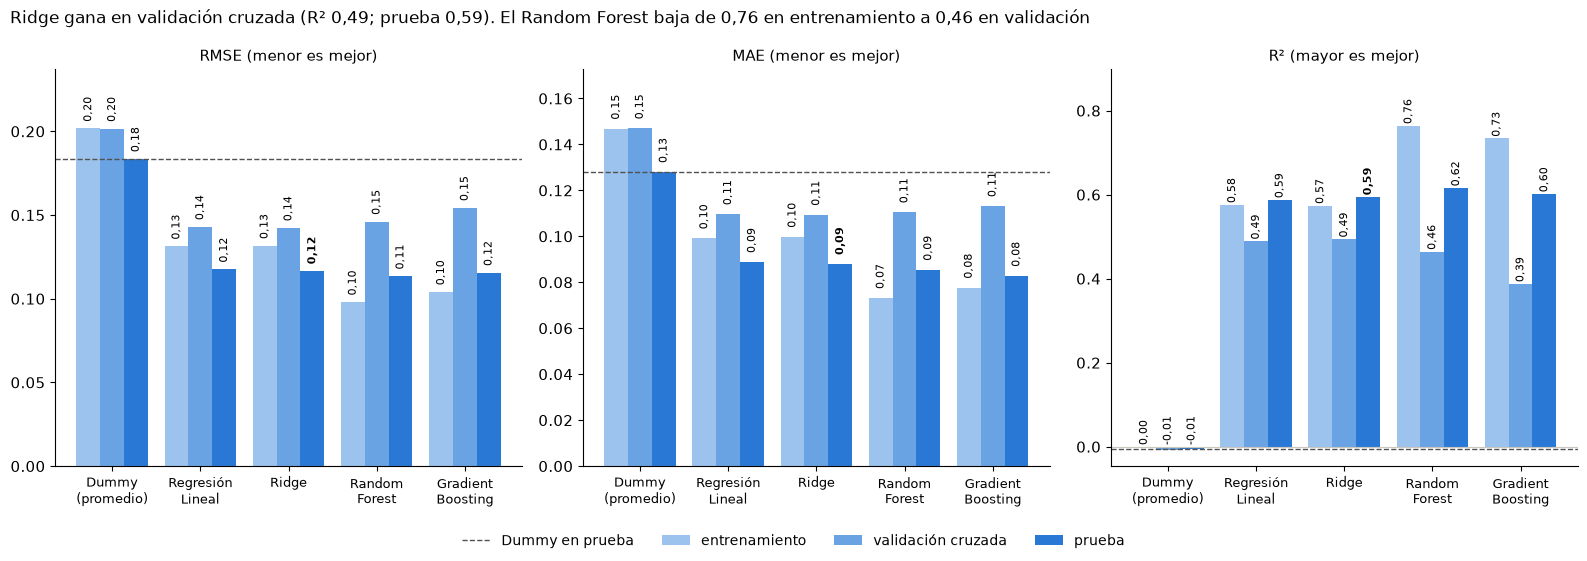

In [10]:
# Gráfico 1: comparación de métricas por modelo.
t2.fig_comparacion(tabla, mejor);

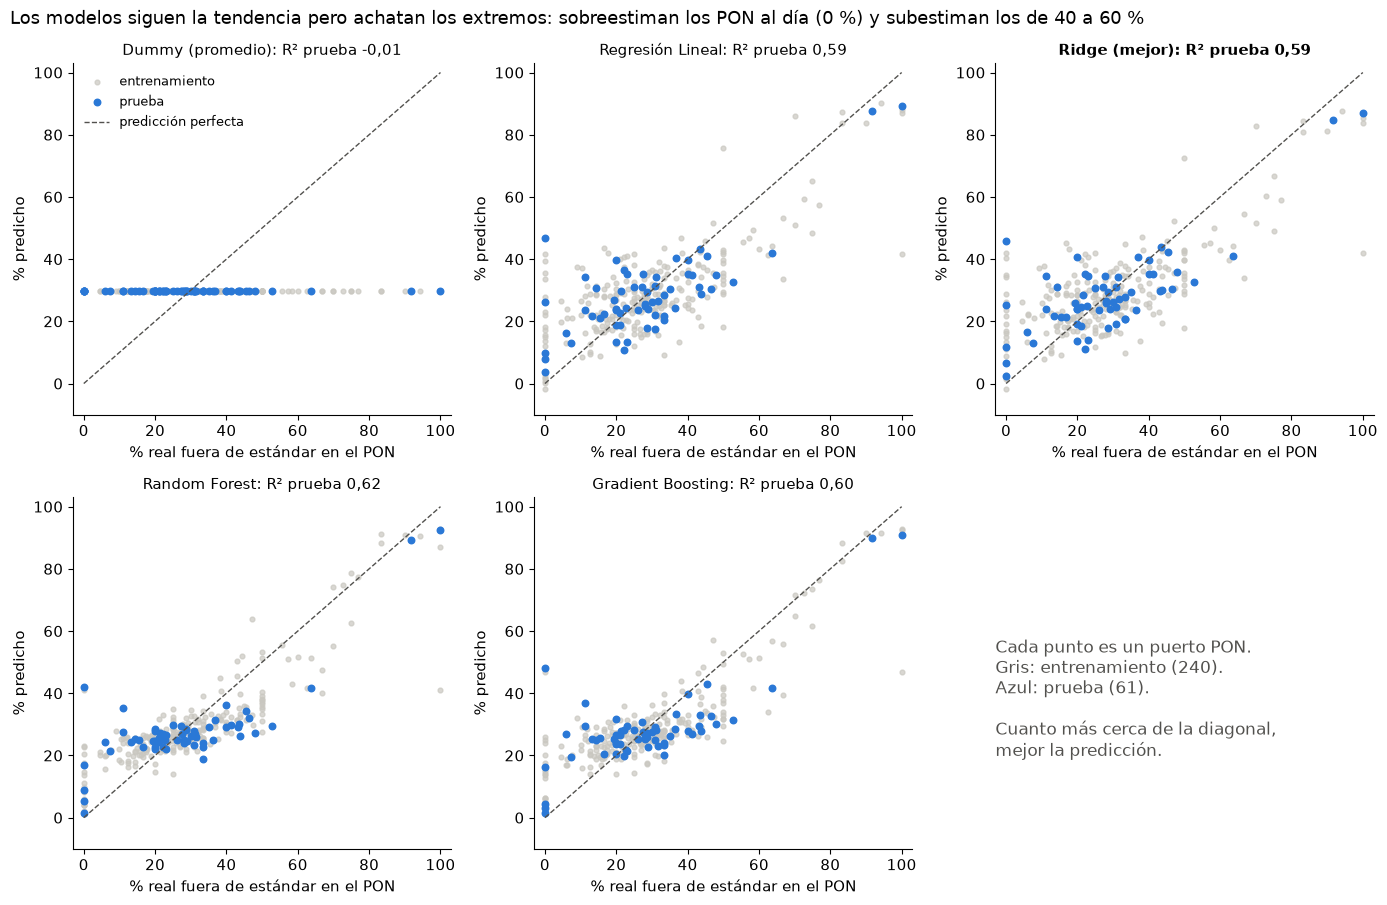

In [11]:
# Gráfico 2: predicho contra real, un panel por modelo.
t2.fig_predicho_vs_real(busquedas, Xtr, ytr, Xte, yte, mejor);

## 9. Búsqueda de hiperparámetros: espacio explorado y mejora

Para cada combinación de la grilla, el RMSE, el MAE y el R² medios de la validación cruzada. Se compara la mejor
combinación con los valores por defecto de scikit-learn.

In [12]:
# Espacio explorado (todas las combinaciones) y mejora respecto de los valores por defecto.
espacio, mejora = t2.mejora_gridsearch(busquedas)
display(espacio.sort_values(["modelo", "ranking"]).round(4))
display(mejora.round(4))

,modelo,hiperparametros,RMSE_cv,RMSE_cv_desvio,MAE_cv,R2_cv,R2_entrenamiento_cv,ranking
0,Dummy (promedio),{},0.202,0.012,0.147,-0.008,0.000,1
11,Gradient Boosting,"{'learning_rate': 0.05, 'max_depth': 2}",0.154,0.021,0.113,0.388,0.769,1
13,Gradient Boosting,"{'learning_rate': 0.1, 'max_depth': 2}",0.165,0.022,0.119,0.297,0.849,2
12,Gradient Boosting,"{'learning_rate': 0.05, 'max_depth': 3}",0.166,0.021,0.119,0.293,0.868,3
14,Gradient Boosting,"{'learning_rate': 0.1, 'max_depth': 3}",0.174,0.022,0.125,0.226,0.932,4
9,Random Forest,"{'max_depth': 8, 'min_samples_leaf': 3}",0.146,0.017,0.110,0.465,0.775,1
10,Random Forest,"{'max_depth': 8, 'min_samples_leaf': 5}",0.146,0.017,0.112,0.465,0.719,2
7,Random Forest,"{'max_depth': None, 'min_samples_leaf': 5}",0.147,0.017,0.113,0.462,0.729,3
6,Random Forest,"{'max_depth': None, 'min_samples_leaf': 3}",0.147,0.017,0.111,0.459,0.807,4
8,Random Forest,"{'max_depth': 8, 'min_samples_leaf': 1}",0.150,0.019,0.111,0.424,0.829,5


,modelo,combinaciones,RMSE_cv_por_defecto,RMSE_cv_mejor,mejora_pct,mejores_hiperparametros
0,Ridge,3,0.142,0.142,0.000,{'alpha': 1}
1,Random Forest,6,0.152,0.146,3.994,"{'max_depth': 8, 'min_samples_leaf': 3}"
2,Gradient Boosting,4,0.174,0.154,11.088,"{'learning_rate': 0.05, 'max_depth': 2}"


## 10. ¿Por qué 5 proporciones de modelo y no las 22?

Con 240 PON de entrenamiento, sumar las 22 proporciones lleva la Regresión Lineal a 38 predictores. El R² de prueba casi no
cambia, pero el R² ajustado se desploma: el modelo gana variables sin ganar información.

In [13]:
# Regresión Lineal con las 5 proporciones principales contra las 22.
comp_shares = t2.comparar_shares(train, test)
display(comp_shares.round(3))

,proporciones,predictores,R2_cv,R2_prueba,R2_ajustado_prueba
0,5 modelos más usados,21,0.489,0.588,0.366
1,los 22 modelos,38,0.457,0.618,-0.043


## 11. Importancia de variables

- **Importancia por permutación** del mejor modelo, sobre la prueba: cuánto cae el R² si se mezcla una variable. Se
  calcula **después** de la evaluación final y no se usa para cambiar el modelo.
- Como `pct_catv` y `share_EG8143A5` están casi perfectamente correlacionadas, también se mezclan **juntas**.
- Para comparar: los coeficientes de la Regresión Lineal (variables escaladas) y la importancia del Random Forest.

Correlación pct_catv / share_EG8143A5 en entrenamiento: 0.993
Caída del R² al mezclarlas juntas: 1.339 ± 0.192


,variable,caida_R2_media,caida_R2_desvio
0,pct_catv,0.914,0.143
1,Localidad,0.267,0.063
2,share_EG8141A5,0.155,0.076
3,share_EG8143A5,0.125,0.032
4,onts,0.019,0.007
5,share_CN1001,0.011,0.009
6,share_RDC143,0.008,0.005
7,pct_moderno,0.007,0.006
8,share_CN2002,0.001,0.004
9,n_modelos,-0.009,0.004


Regresión Lineal (coeficientes)             Random Forest (importancia)            
                               variable coeficiente                    variable importancia
0                   Localidad_Larrechea       0.309                    pct_catv       0.343
1                              pct_catv       0.161              share_EG8143A5       0.267
2                        share_EG8141A5       0.095              share_EG8141A5       0.132
3        Localidad_Bernardo de Irigoyen      -0.087                        onts       0.101
4                    Localidad_Frontera      -0.066                   n_modelos       0.032
5  Localidad_Santa Clara de Buena Vista      -0.065                share_CN1001       0.024
6                      Localidad_Sastre      -0.059                share_CN2002       0.016
7   Localidad_San Martin de las Escobas      -0.054                share_RDC143       0.014

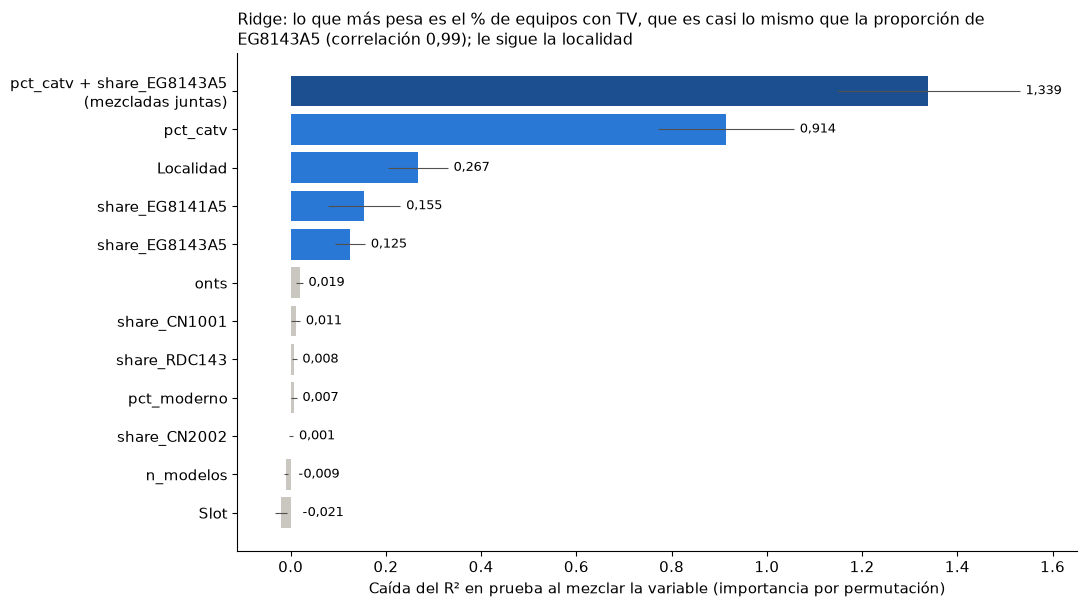

In [14]:
# Importancia del mejor modelo, del par casi redundante y de los otros modelos.
pipe = busquedas[mejor].best_estimator_
imp = t2.importancia(pipe, Xte, yte)
grupo_catv = t2.importancia_grupo(pipe, Xte, yte, ["pct_catv", "share_EG8143A5"])
corr_catv = float(Xtr["pct_catv"].corr(Xtr["share_EG8143A5"]))
print(f"Correlación pct_catv / share_EG8143A5 en entrenamiento: {corr_catv:.3f}")
print(f"Caída del R² al mezclarlas juntas: {grupo_catv[0]:.3f} ± {grupo_catv[1]:.3f}")
display(imp.round(3))
coef = t2.coeficientes_lineales(busquedas["Regresión Lineal"].best_estimator_)
imp_rf = t2.importancia_arboles(busquedas["Random Forest"].best_estimator_)
display(pd.concat([coef.head(8).reset_index(drop=True), imp_rf.head(8).reset_index(drop=True)], axis=1,
                  keys=["Regresión Lineal (coeficientes)", "Random Forest (importancia)"]).round(3))
t2.fig_importancia(imp, mejor, grupo_catv, corr_catv);

**Lectura.** El % de equipos con TV es casi lo mismo que la proporción de EG8143A5, el único modelo con TV que es común.
En ese modelo el firmware estándar es la V3 y la mayoría de los equipos tiene V5. Por eso, cuantos más EG8143A5 tiene un
puerto, más alto le da el porcentaje "fuera de estándar". Parte de lo que el modelo aprende es la definición del estándar:
hay que validarla con la empresa.

## 12. Análisis de residuos del mejor modelo

Residuo = real − predicho.
- **Fuera de muestra en el entrenamiento** (`cross_val_predict` con el mismo KFold, 240 PON) y **en la prueba** (61 PON).
- **Normalidad:** test de Shapiro-Wilk.
- **Homocedasticidad:** test de Breusch-Pagan (versión de Koenker), con el valor predicho como regresor.
- **Patrones no capturados:** relación del error con el tamaño del puerto y residuo medio por localidad.

,n,media,desvio,asimetria,shapiro_W,shapiro_p,breusch_pagan_LM,breusch_pagan_p
cv_entrenamiento,240.0,-0.001,0.143,-0.101,0.982,0.003,5.680,0.017
prueba,61.0,-0.003,0.117,-1.003,0.945,0.008,2.576,0.108


Spearman |residuo| vs ONTs del PON: -0.35 (p = 1.8e-08)
MAE en PON con <= 5 equipos (35): 0.157 | en el resto: 0.101
Residuo medio por localidad (CV): {'Bernardo de Irigoyen': -0.0078, 'Castelar / Crispi': -0.0014, 'Frontera': -0.0034, 'Larrechea': 0.0269, 'Lopez': 0.0072, 'San Martin de las Escobas': -0.006, 'San Vicente': 0.0021, 'Santa Clara de Buena Vista': -0.0048, 'Sastre': -0.0055}
cv_entrenamiento: NO normales (Shapiro p = 0.0032); heterocedásticos (Breusch-Pagan p = 0.017)
prueba: NO normales (Shapiro p = 0.0083); sin evidencia de heterocedasticidad (Breusch-Pagan p = 0.109)


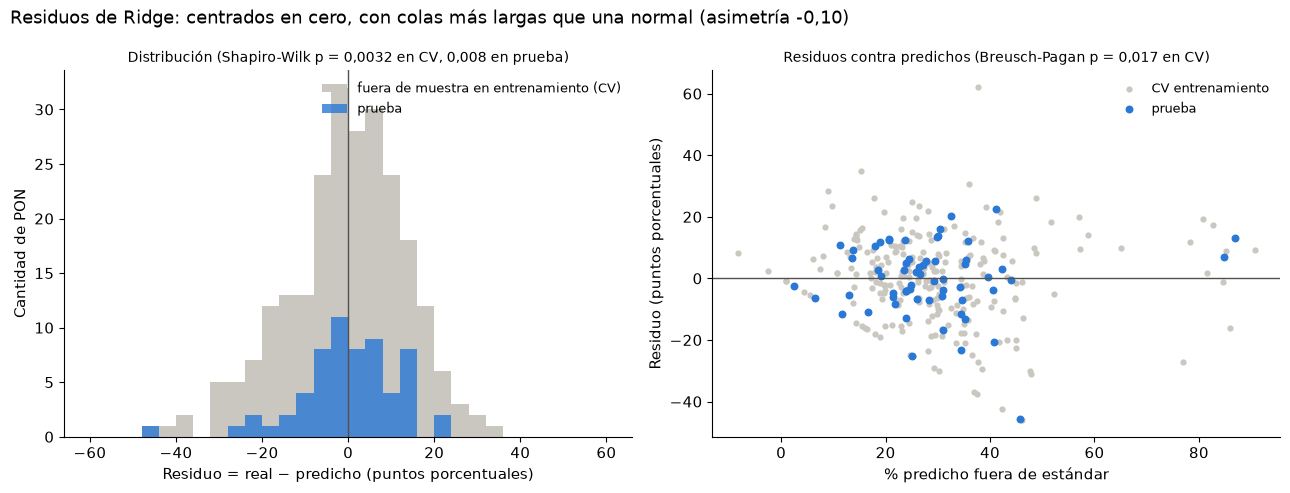

In [15]:
# Residuos: tests y patrones.
res, oof = t2.analisis_residuos(pipe, Xtr, ytr, Xte, yte)
display(pd.DataFrame({k: v for k, v in res.items() if k != "patrones"}).T.round(4))
pat = res["patrones"]
print(f"Spearman |residuo| vs ONTs del PON: {pat['spearman_abs_residuo_vs_onts']:.2f} (p = {pat['spearman_p']:.1e})")
print(f"MAE en PON con <= 5 equipos ({pat['n_pon_5_onts_o_menos']}): {pat['MAE_pon_5_onts_o_menos']:.3f} | "
      f"en el resto: {pat['MAE_pon_mas_de_5_onts']:.3f}")
print("Residuo medio por localidad (CV):", pat["residuo_medio_por_localidad"])
for nombre in ["cv_entrenamiento", "prueba"]:
    r = res[nombre]
    print(f"{nombre}: {'NO ' if r['shapiro_p'] < 0.05 else ''}normales (Shapiro p = {r['shapiro_p']:.4f}); "
          f"{'heterocedásticos' if r['breusch_pagan_p'] < 0.05 else 'sin evidencia de heterocedasticidad'} "
          f"(Breusch-Pagan p = {r['breusch_pagan_p']:.3f})")
t2.fig_residuos(ytr, oof, yte, pipe.predict(Xte), res, mejor);

## 13. Curva de aprendizaje

RMSE de entrenamiento y de validación según la cantidad de PON usados para entrenar. Se grafica el mejor modelo y el Random
Forest para comparar: si las curvas quedan separadas, el modelo tiene varianza alta; si se juntan en un error alto, el
límite es el sesgo.

,n_entrenamiento,RMSE_entrenamiento,RMSE_entrenamiento_desvio,RMSE_validacion,RMSE_validacion_desvio,modelo
0,57,0.100,0.014,0.162,0.011,Ridge (mejor)
1,76,0.110,0.015,0.160,0.016,Ridge (mejor)
2,96,0.117,0.013,0.157,0.016,Ridge (mejor)
3,115,0.124,0.006,0.148,0.018,Ridge (mejor)
4,134,0.122,0.005,0.148,0.018,Ridge (mejor)
5,153,0.126,0.003,0.144,0.014,Ridge (mejor)
6,172,0.129,0.004,0.143,0.015,Ridge (mejor)
7,192,0.130,0.004,0.142,0.015,Ridge (mejor)


,n_entrenamiento,RMSE_entrenamiento,RMSE_entrenamiento_desvio,RMSE_validacion,RMSE_validacion_desvio,modelo
0,57,0.096,0.016,0.163,0.017,Random Forest
1,76,0.091,0.015,0.159,0.017,Random Forest
2,96,0.089,0.010,0.158,0.016,Random Forest
3,115,0.092,0.004,0.150,0.019,Random Forest
4,134,0.088,0.002,0.149,0.020,Random Forest
5,153,0.091,0.003,0.148,0.019,Random Forest
6,172,0.093,0.005,0.147,0.017,Random Forest
7,192,0.095,0.004,0.145,0.017,Random Forest


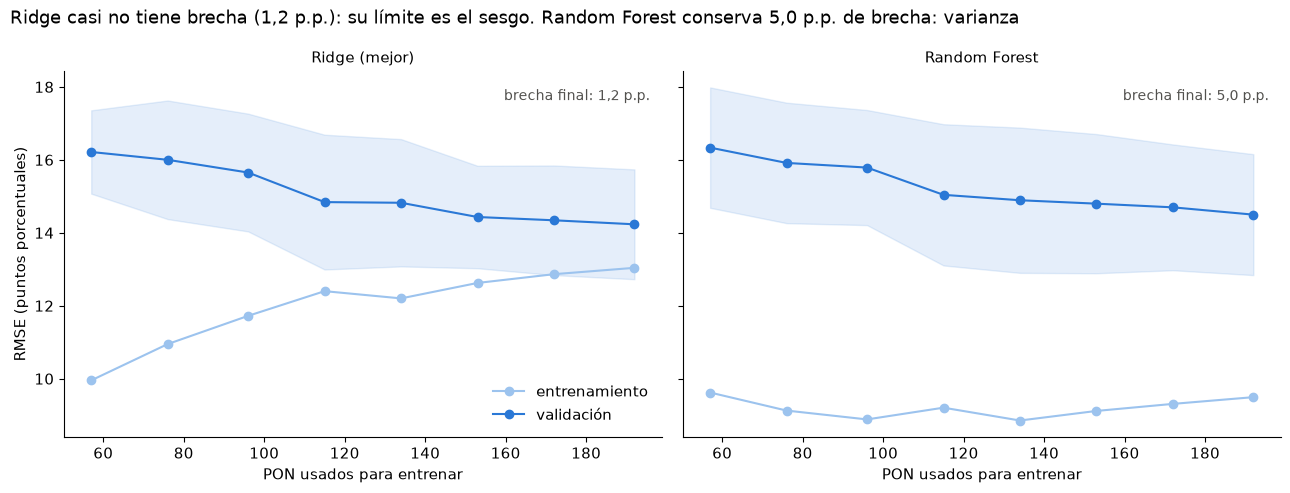

In [16]:
# Curvas de aprendizaje (KFold de 5 sobre el entrenamiento).
curvas = {f"{mejor} (mejor)": t2.curva_aprendizaje(pipe, Xtr, ytr)}
if mejor != "Random Forest":
    curvas["Random Forest"] = t2.curva_aprendizaje(busquedas["Random Forest"].best_estimator_, Xtr, ytr)
for n, c in curvas.items():
    display(c.assign(modelo=n).round(4))
t2.fig_curva_aprendizaje(curvas);

## 14. Prueba extra: ¿sumar los datos de la OLT mejora la predicción?

Del listado de la OLT del 29/10/2026 se arman tres variables por PON:
- % de equipos online;
- distancia mediana a la OLT (km);
- potencia recibida mediana de los equipos online (dBm).

Se repite el mejor modelo con la misma partición y la misma grilla. Los PON sin datos de la OLT se imputan con la mediana
dentro del pipeline. La hipótesis es que **no** mejora: el firmware desactualizado es un tema administrativo (qué se
actualizó y dónde), no técnico.

In [17]:
# Mejor modelo sin y con las variables de la OLT.
olt_tabla, olt_cob = t2.prueba_olt(mejor, train, test, numericas)
display(olt_tabla.round(3))
print("Cobertura y correlación con el objetivo:", olt_cob)

,variables,predictores,R2_cv,MAE_cv,RMSE_cv,R2_prueba,R2_ajustado_prueba,MAE_prueba,RMSE_prueba
0,sin OLT,21,0.494,0.109,0.142,0.595,0.376,0.088,0.117
1,con OLT,24,0.464,0.113,0.146,0.508,0.179,0.096,0.128


Cobertura y correlación con el objetivo: {'pon_con_datos_olt_entrenamiento': 239, 'pon_entrenamiento': 240, 'pon_con_datos_olt_prueba': 61, 'pon_prueba': 61, 'corr_spearman_con_objetivo': {'olt_pct_online': -0.10691197962542, 'olt_dist_mediana_km': 0.18430577199235854, 'olt_rxp_mediana_dbm': -0.20623850859325368}}


## 15. Criterio SMART (objetivo 9)

Sobre el mejor modelo, en prueba:
- R² ≥ 0,45;
- R² ajustado ≥ 0,30;
- MAE menor que el del Dummy en la misma prueba.

In [18]:
# Evaluación del criterio SMART.
smart = t2.criterio_smart(tabla, mejor)
display(smart.round(3))
print("Se cumple el criterio completo:", bool(smart["cumple"].all()))

,criterio,umbral,valor,cumple
0,R² en prueba,>= 0.45,0.595,True
1,R² ajustado en prueba,>= 0.3,0.376,True
2,MAE en prueba menor que el del Dummy,< 0.128,0.088,True


Se cumple el criterio completo: True


## 16. Guardar resultados y borradores

Se guardan las tablas y figuras en `reports/TP2/`, las predicciones de prueba en `results/` y todas las cifras en
`results/metrics.json` (clave `obj09_tp2`). Después se regeneran los borradores del informe y del cuestionario a partir de
esas cifras.

In [19]:
# Guardado: mismo diccionario de resultados que arma t2.correr() desde run_all.py.
r = dict(pons=pons, train=train, test=test, shares=shares, numericas=numericas, cols=cols,
         Xtr=Xtr, ytr=ytr, Xte=Xte, yte=yte, busquedas=busquedas, tabla=tabla, diag=diag, mejor=mejor,
         espacio=espacio, mejora=mejora, imp=imp, grupo_catv=grupo_catv, corr_catv=corr_catv,
         comp_shares=comp_shares, coef=coef, imp_rf=imp_rf, res=res, oof=oof, curvas=curvas,
         olt_tabla=olt_tabla, olt_cob=olt_cob, smart=smart)
t2.guardar_todo(r)

from tp2_informe import escribir
for ruta in escribir():
    print("Borrador:", ruta.relative_to(RAIZ))
print(sorted(p.name for p in (RAIZ / "reports" / "TP2").iterdir()))

Borrador: reports\TP2\informe_borrador.md
Borrador: reports\TP2\cuestionario_borrador.md
['coeficientes_regresion_lineal.csv', 'comparacion_5_vs_22_modelos.csv', 'criterio_smart.csv', 'cuestionario_borrador.md', 'curva_aprendizaje_random_forest.csv', 'curva_aprendizaje_ridge.csv', 'diagnostico_ajuste.csv', 'gridsearch_espacio.csv', 'gridsearch_mejora.csv', 'importancia_permutacion.csv', 'importancia_random_forest.csv', 'informe_borrador.md', 'prueba_olt.csv', 'tabla_metricas.csv', 'tp2_comparacion_modelos.png', 'tp2_curva_aprendizaje.png', 'tp2_importancia_variables.png', 'tp2_predicho_vs_real.png', 'tp2_residuos.png']


## 17. Conclusiones

Las cifras de esta sección salen del código (celda de abajo). El borrador del informe y las respuestas al cuestionario
están en `reports/TP2/informe_borrador.md` y `reports/TP2/cuestionario_borrador.md`.

In [20]:
# Resumen final con las cifras obtenidas.
p, cvm = t2.pivote(tabla, "R2")["prueba"], t2.pivote(tabla, "R2")["validación cruzada (media)"]
mae = t2.pivote(tabla, "MAE")["prueba"]
print(f"1. Mejor modelo: {mejor}. R² de prueba {p[mejor]:.2f} (CV {cvm[mejor]:.2f}); "
      f"MAE {mae[mejor]:.3f} contra {mae['Dummy (promedio)']:.3f} del Dummy.")
print(f"2. La Regresión Lineal (línea base) queda prácticamente igual: R² CV {cvm['Regresión Lineal']:.3f}.")
print(f"3. Random Forest y Gradient Boosting sobreajustan: R² de entrenamiento "
      f"{t2.pivote(tabla, 'R2').loc['Random Forest', 'entrenamiento']:.2f} y "
      f"{t2.pivote(tabla, 'R2').loc['Gradient Boosting', 'entrenamiento']:.2f} contra {cvm['Random Forest']:.2f} y "
      f"{cvm['Gradient Boosting']:.2f} en CV.")
print(f"4. Las variables de la OLT no mejoran: R² CV {olt_tabla.loc[0, 'R2_cv']:.3f} sin OLT contra "
      f"{olt_tabla.loc[1, 'R2_cv']:.3f} con OLT.")
print(f"5. Criterio SMART: {'se cumple' if smart['cumple'].all() else 'NO se cumple completo'}.")

1. Mejor modelo: Ridge. R² de prueba 0.59 (CV 0.49); MAE 0.088 contra 0.128 del Dummy.
2. La Regresión Lineal (línea base) queda prácticamente igual: R² CV 0.489.
3. Random Forest y Gradient Boosting sobreajustan: R² de entrenamiento 0.76 y 0.73 contra 0.46 y 0.39 en CV.
4. Las variables de la OLT no mejoran: R² CV 0.494 sin OLT contra 0.464 con OLT.
5. Criterio SMART: se cumple.
